Muestras: 900  Resolucion: 0.0333 Hz = 2.0 lpm
FC real: 72.0 lpm   FC estimada: 72.00 lpm
real=  55.0  estimada=  55.25  error=+0.25
real=  65.0  estimada=  65.00  error=+0.00
real=  72.0  estimada=  72.00  error=+0.00
real=  85.0  estimada=  85.00  error=+0.00
real= 100.0  estimada= 100.00  error=+0.00
real= 120.0  estimada= 120.00  error=+0.00
MAE = 0.04 lpm   RMSE = 0.10 lpm


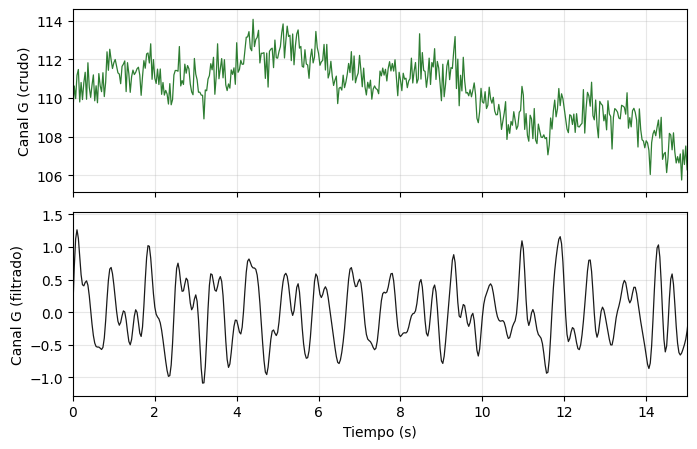

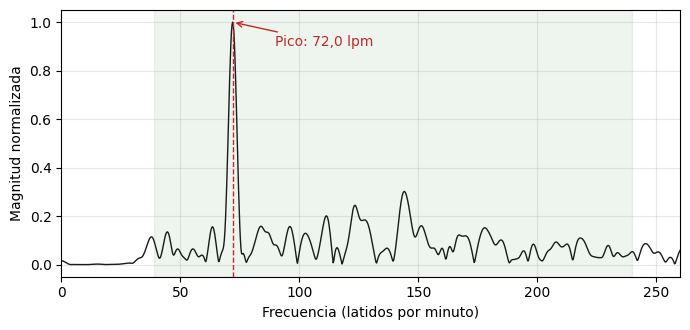

In [ ]:
import numpy as np
from scipy.signal import butter, filtfilt
import matplotlib.pyplot as plt

FS = 30.0          # frecuencia de muestreo = fps de la camara
DURACION = 30.0    # segundos de video
F_MIN, F_MAX = 0.65, 4.0   # banda cardiaca en Hz (aprox. 40-240 lpm)


def senal_sintetica(fc_lpm, fs=FS, duracion=DURACION, semilla=0):
    """Simula el promedio R, G, B de la ROI en cada frame."""
    rng = np.random.default_rng(semilla)
    t = np.arange(0, duracion, 1 / fs)
    f0 = fc_lpm / 60.0                                  # lpm -> Hz
    pulso = np.sin(2 * np.pi * f0 * t) + 0.3 * np.sin(2 * np.pi * 2 * f0 * t)
    respiracion = np.sin(2 * np.pi * 0.25 * t)          # 15 respiraciones/min
    deriva = 2.0 * np.sin(2 * np.pi * 0.05 * t)         # cambio lento de luz
    base = {"R": 150.0, "G": 110.0, "B": 90.0}          # nivel medio del canal
    amp = {"R": 0.25, "G": 0.50, "B": 0.20}             # el pulso pesa mas en G
    rgb = {}
    for c in "RGB":
        ruido = rng.normal(0, 0.6, t.size)
        rgb[c] = base[c] + amp[c] * pulso + 0.8 * respiracion + deriva + ruido
    return t, rgb


def pasa_banda(x, fs=FS, f1=F_MIN, f2=F_MAX, orden=3):
    """Filtro Butterworth pasa-banda de fase cero."""
    b, a = butter(orden, [f1, f2], btype="bandpass", fs=fs)
    return filtfilt(b, a, x)


def estimar_fc(x, fs=FS, f1=F_MIN, f2=F_MAX):
    """Devuelve la FC (lpm) como el pico del espectro dentro de la banda."""
    x = (x - x.mean()) * np.hanning(x.size)
    n_fft = 8 * x.size                                   # relleno con ceros
    espectro = np.abs(np.fft.rfft(x, n_fft))
    f = np.fft.rfftfreq(n_fft, 1 / fs)
    banda = (f >= f1) & (f <= f2)
    f_pico = f[banda][np.argmax(espectro[banda])]
    return 60.0 * f_pico, f, espectro


if __name__ == "__main__":
    # --- Caso principal: FC real de 72 lpm ---
    t, rgb = senal_sintetica(72, semilla=1)
    g = rgb["G"]
    g_filt = pasa_banda(g)
    fc, f, esp = estimar_fc(g_filt)
    print(f"Muestras: {t.size}  Resolucion: {FS / t.size:.4f} Hz = {60 * FS / t.size:.1f} lpm")
    print(f"FC real: 72.0 lpm   FC estimada: {fc:.2f} lpm")

    # --- Figura 1: senal cruda y filtrada ---
    fig, ax = plt.subplots(2, 1, figsize=(7, 4.6), sharex=True)
    ax[0].plot(t, g, color="#2e7d32", lw=0.9)
    ax[0].set_ylabel("Canal G (crudo)")
    ax[1].plot(t, g_filt, color="#1a1a1a", lw=0.9)
    ax[1].set_ylabel("Canal G (filtrado)")
    ax[1].set_xlabel("Tiempo (s)")
    ax[1].set_xlim(0, 15)
    for a in ax:
        a.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig("fig_senal.png", dpi=200)

    # --- Figura 2: espectro ---
    fig, ax = plt.subplots(figsize=(7, 3.4))
    lpm = 60 * f
    ax.plot(lpm, esp / esp.max(), color="#1a1a1a", lw=1.0)
    ax.axvspan(60 * F_MIN, 60 * F_MAX, color="#2e7d32", alpha=0.08)
    ax.axvline(fc, color="#c62828", ls="--", lw=1.0)
    ax.annotate(f"Pico: {fc:.1f} lpm".replace(".", ","), xy=(fc, 1.0), xytext=(fc + 18, 0.9),
                arrowprops=dict(arrowstyle="->", color="#c62828"), color="#c62828")
    ax.set_xlim(0, 260)
    ax.set_xlabel("Frecuencia (latidos por minuto)")
    ax.set_ylabel("Magnitud normalizada")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig("fig_espectro.png", dpi=200)

    # --- Barrido: varias FC reales, metricas de error ---
    reales = [55, 65, 72, 85, 100, 120]
    estimadas = []
    for i, fc_real in enumerate(reales):
        _, s = senal_sintetica(fc_real, semilla=10 + i)
        est, _, _ = estimar_fc(pasa_banda(s["G"]))
        estimadas.append(est)
        print(f"real={fc_real:6.1f}  estimada={est:7.2f}  error={est - fc_real:+.2f}")
    err = np.array(estimadas) - np.array(reales)
    print(f"MAE = {np.mean(np.abs(err)):.2f} lpm   RMSE = {np.sqrt(np.mean(err ** 2)):.2f} lpm")
